# Identificação do projeto

**Título do projeto:** Perfil das faixas populares nos charts da Deezer por gênero  
**Integrantes do grupo:** Eduardo Fabri, João Correa, Rodrigo Alves e João Pedro Cardoso  
**Turma:** Bacharelado em Sistemas de Informação • 2º semestre de 2026  
**Descrição breve do problema ou contexto:** os charts da Deezer dizem quais faixas estão no topo de cada gênero, mas não o que elas têm em comum. Este notebook usa o conjunto preparado no RA1 para descrever e comparar, entre gêneros, a duração das faixas, a idade do lançamento, a popularidade do artista e a concentração de artistas no ranking, e testa uma previsão simples com Machine Learning.

---

# RA3 — Analysis, Visualization and Machine Learning

Utilize os dados preparados e processados nas etapas anteriores para produzir análises estatísticas, visualizações e interpretações que contribuam para responder ao problema definido. Explore também uma aplicação simples de Machine Learning, por classificação ou regressão, para investigar uma possibilidade de previsão a partir dos dados.

## 1. Análise estatística descritiva

Realize uma análise estatística dos dados, contemplando:

- **Tendência central:** utilização de média e/ou mediana para compreender valores representativos.
- **Dispersão:** utilização de medidas como amplitude ou desvio-padrão para analisar a variabilidade.
- **Distribuição:** investigação da frequência, concentração ou distribuição dos valores.

As medidas utilizadas devem ser coerentes com as características dos dados e com o problema investigado. Apresente os resultados e explique o que eles representam no contexto do projeto.

In [1]:
# Preparação do ambiente: bibliotecas, pastas do projeto e origem dos dados
import subprocess
import sys
from pathlib import Path

import pandas as pd

URL_REPOSITORIO = "https://github.com/Jcliz/machine-learning-ra3.git"
PASTA_CLONE = "machine-learning-ra3"
RAMO = "main"  # no Colab, troque pelo ramo do repositório que quiser executar
NO_COLAB = "google.colab" in sys.modules

if NO_COLAB:
    if Path(PASTA_CLONE).exists():
        # Clone de uma execução anterior nesta sessão do Colab: traz a versão mais nova do ramo
        subprocess.run(["git", "-C", PASTA_CLONE, "pull", "-q", "origin", RAMO], check=False)
    else:
        subprocess.run(["git", "clone", "-q", "-b", RAMO, URL_REPOSITORIO], check=True)

# O conjunto preparado fica em dados/ no repositório da entrega e em dados/preparados/ no de desenvolvimento
candidatos = [Path(PASTA_CLONE), Path.cwd(), Path.cwd().parent]
encontrados = [
    (p.resolve(), arquivo.resolve())
    for p in candidatos if (p / "requirements.txt").exists()
    for arquivo in (p / "dados" / "faixas_preparadas.csv", p / "dados" / "preparados" / "faixas_preparadas.csv")
    if arquivo.exists()
]
if not encontrados:
    raise FileNotFoundError(
        "Conjunto preparado não encontrado (dados/faixas_preparadas.csv ao lado do requirements.txt). "
        f"Rode o notebook de dentro do clone (raiz ou notebook/) ou, no Colab, confira o ramo '{RAMO}'."
    )
RAIZ, ARQUIVO_PREPARADO = encontrados[0]
PASTA_PREPARADOS = ARQUIVO_PREPARADO.parent

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
print(f"Raiz do projeto: {RAIZ.name}")  # só o nome da pasta: o caminho completo é da máquina de quem executa
print(f"Ambiente: {'Google Colab' if NO_COLAB else 'local'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

Raiz do projeto: data-analytics
Ambiente: local · Python 3.13.7 · pandas 2.3.3


In [2]:
# Releitura do conjunto preparado para a análise
colunas_inteiras_analise = ["id_faixa", "id_chart", "posicao_chart", "id_artista", "id_album",
                            "duracao_s", "rank", "numero_fas"]
colunas_texto_analise = ["titulo", "genero", "tipo_chart", "artista"]
colunas_booleanas_analise = ["lancamento_posterior_coleta", "duracao_fora_limites_iqr"]
df_analise = pd.read_csv(
    ARQUIVO_PREPARADO, encoding="utf-8",
    dtype={**{c: "int64" for c in colunas_inteiras_analise},
           **{c: "string" for c in colunas_texto_analise},
           **{c: "bool" for c in colunas_booleanas_analise}},
    parse_dates=["data_lancamento", "data_coleta"],
)
print(f"{len(df_analise)} ocorrências faixa-chart, {df_analise['id_faixa'].nunique()} faixas distintas, "
      f"{df_analise.loc[df_analise['tipo_chart'].eq('genero'), 'genero'].nunique()} charts de gênero "
      f"e {df_analise['tipo_chart'].eq('geral').sum()} ocorrências no chart geral.")

2800 ocorrências faixa-chart, 2581 faixas distintas, 27 charts de gênero e 100 ocorrências no chart geral.


In [3]:
# Recorte da análise e idade da faixa na coleta
from IPython.display import display


def numero_br_desc(valor, casas=1):
    """Formata um número no padrão brasileiro (1.234,5)."""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def mostrar_desc(tabela, casas=1):
    """Mostra uma tabela com os números no padrão brasileiro, sem mudar a configuração das outras seções."""
    with pd.option_context("display.float_format", lambda valor: numero_br_desc(valor, casas)):
        display(tabela)


# Comparações entre gêneros usam só os charts de gênero; o chart geral fica como referência à parte
df_generos_desc = df_analise.loc[df_analise["tipo_chart"].eq("genero")].copy()
df_geral_desc = df_analise.loc[df_analise["tipo_chart"].eq("geral")].copy()

# Idade da faixa = dias entre o lançamento e a coleta; o lançamento posterior à coleta não tem idade
for recorte_desc in (df_generos_desc, df_geral_desc):
    recorte_desc["idade_dias"] = (recorte_desc["data_coleta"] - recorte_desc["data_lancamento"]).dt.days
    recorte_desc.loc[recorte_desc["lancamento_posterior_coleta"], "idade_dias"] = pd.NA
    recorte_desc["idade_anos"] = recorte_desc["idade_dias"] / 365.25

print(f"Charts de gênero: {len(df_generos_desc)} ocorrências em {df_generos_desc['genero'].nunique()} charts "
      f"({df_generos_desc.groupby('genero').size().min()} a {df_generos_desc.groupby('genero').size().max()} por chart), "
      f"{df_generos_desc['id_faixa'].nunique()} faixas distintas.")
print(f"Chart geral (referência à parte): {len(df_geral_desc)} ocorrências.")
print(f"Ocorrências sem idade por lançamento posterior à coleta: "
      f"{df_generos_desc['idade_dias'].isna().sum()} nos gêneros e {df_geral_desc['idade_dias'].isna().sum()} no geral.")

Charts de gênero: 2700 ocorrências em 27 charts (100 a 100 por chart), 2578 faixas distintas.
Chart geral (referência à parte): 100 ocorrências.
Ocorrências sem idade por lançamento posterior à coleta: 1 nos gêneros e 0 no geral.


In [4]:
# Forma de cada variável e medida de centro escolhida
variaveis_desc = {
    "duracao_s": "Duração (s) — P1",
    "idade_anos": "Idade na coleta (anos) — P2",
    "rank": "Rank — P3",
    "numero_fas": "Fãs do artista — P3",
}


def resumir_desc(serie):
    """Tendência central, dispersão e forma de uma variável numérica."""
    serie = serie.dropna().astype("float64")
    q1, q3 = serie.quantile([0.25, 0.75])
    return pd.Series({
        "n": len(serie),
        "média": serie.mean(),
        "mediana": serie.median(),
        "média/mediana": serie.mean() / serie.median(),
        "desvio-padrão": serie.std(),
        "mínimo": serie.min(),
        "1º quartil": q1,
        "3º quartil": q3,
        "máximo": serie.max(),
        "amplitude": serie.max() - serie.min(),
        "IQR": q3 - q1,
        "assimetria": serie.skew(),
    })


forma_desc = pd.DataFrame({rotulo: resumir_desc(df_generos_desc[coluna])
                           for coluna, rotulo in variaveis_desc.items()}).T
# Regra do grupo: com assimetria acima de 1 em módulo, a média se afasta do centro; vale a mediana com o IQR
forma_desc["centro escolhido"] = forma_desc["assimetria"].abs().gt(1).map(
    {True: "mediana + IQR", False: "média ≈ mediana + desvio-padrão"})
mostrar_desc(forma_desc.T, casas=2)  # uma coluna por variável, uma linha por medida

,Duração (s) — P1,Idade na coleta (anos) — P2,Rank — P3,Fãs do artista — P3
n,"2.700,00","2.699,00","2.700,00","2.700,00"
média,"229,44","10,39","441.632,31","1.180.927,61"
mediana,"213,00","5,86","439.398,00","64.585,50"
média/mediana,"1,08","1,77","1,01","18,28"
desvio-padrão,"98,83","12,52","271.062,97","2.859.197,01"
mínimo,"41,00","0,01","807,00","0,00"
1º quartil,"179,00","1,23","209.772,50","5.321,75"
3º quartil,"255,00","15,34","649.024,00","732.504,25"
máximo,"2.120,00","96,52","999.724,00","24.109.325,00"
amplitude,"2.079,00","96,52","998.917,00","24.109.325,00"


In [5]:
# P1 — Duração por gênero: centro, dispersão e extremos
duracao_desc = df_generos_desc.groupby("genero").agg(
    mediana_s=("duracao_s", "median"),
    media_s=("duracao_s", "mean"),
    q1_s=("duracao_s", lambda serie: serie.quantile(0.25)),
    q3_s=("duracao_s", lambda serie: serie.quantile(0.75)),
    desvio_s=("duracao_s", "std"),
    minimo_s=("duracao_s", "min"),
    maximo_s=("duracao_s", "max"),
    extremos_iqr=("duracao_fora_limites_iqr", "sum"),
)
duracao_desc["iqr_s"] = duracao_desc["q3_s"] - duracao_desc["q1_s"]
duracao_desc["amplitude_s"] = duracao_desc["maximo_s"] - duracao_desc["minimo_s"]
duracao_desc["media_menos_mediana_s"] = duracao_desc["media_s"] - duracao_desc["mediana_s"]
duracao_desc = duracao_desc.sort_values("mediana_s")
mostrar_desc(duracao_desc[["mediana_s", "media_s", "media_menos_mediana_s", "iqr_s", "desvio_s",
                           "minimo_s", "maximo_s", "amplitude_s", "extremos_iqr"]])

menor_desc, maior_desc = duracao_desc.index[0], duracao_desc.index[-1]
print(f"Mediana da duração entre gêneros: de {numero_br_desc(duracao_desc['mediana_s'].min())} s ({menor_desc}) "
      f"a {numero_br_desc(duracao_desc['mediana_s'].max())} s ({maior_desc}); "
      f"diferença de {numero_br_desc(duracao_desc['mediana_s'].max() - duracao_desc['mediana_s'].min())} s.")
print(f"Maior IQR: {duracao_desc['iqr_s'].idxmax()} ({numero_br_desc(duracao_desc['iqr_s'].max())} s); "
      f"menor IQR: {duracao_desc['iqr_s'].idxmin()} ({numero_br_desc(duracao_desc['iqr_s'].min())} s).")
print(f"Maior distância entre média e mediana: {duracao_desc['media_menos_mediana_s'].idxmax()} "
      f"(+{numero_br_desc(duracao_desc['media_menos_mediana_s'].max())} s).")
print(f"Chart geral (referência): mediana {numero_br_desc(df_geral_desc['duracao_s'].median())} s, "
      f"IQR {numero_br_desc(df_geral_desc['duracao_s'].quantile(0.75) - df_geral_desc['duracao_s'].quantile(0.25))} s.")

,mediana_s,media_s,media_menos_mediana_s,iqr_s,desvio_s,minimo_s,maximo_s,amplitude_s,extremos_iqr
genero,,,,,,,,,
Kids,"159,5","181,9","22,4","71,0","96,9",41,599,558,6
Asian Music,"184,0","186,7","2,7","40,0","32,5",113,305,192,0
Traditional Mexicano,"188,5","194,5","6,0","44,2","35,3",111,336,225,0
Country,"191,0","198,1","7,1","43,2","34,8",151,345,194,0
Brazilian Music,"191,5","205,5","14,0","87,2","72,4",90,487,397,4
Latin Music,"194,5","208,2","13,7","70,0","50,1",123,381,258,2
Films/Games,"196,5","200,5","4,0","88,5","64,3",45,377,332,2
African Music,"200,5","240,8","40,3","82,8","119,9",117,821,704,14
Blues,"201,0","225,3","24,3","76,5","84,8",87,578,491,9


Mediana da duração entre gêneros: de 159,5 s (Kids) a 258,5 s (Metal); diferença de 99,0 s.
Maior IQR: Classical (239,8 s); menor IQR: Asian Music (40,0 s).
Maior distância entre média e mediana: Classical (+86,7 s).
Chart geral (referência): mediana 194,0 s, IQR 49,2 s.


In [6]:
# P1 — Frequência da duração por intervalos de minutos
limites_duracao_desc = [0, 120, 180, 240, 300, 420, float("inf")]
rotulos_duracao_desc = ["até 2 min", "2 a 3 min", "3 a 4 min", "4 a 5 min", "5 a 7 min", "mais de 7 min"]
intervalo_duracao_desc = pd.cut(df_generos_desc["duracao_s"], bins=limites_duracao_desc,
                                labels=rotulos_duracao_desc, right=True)
frequencia_duracao_desc = intervalo_duracao_desc.value_counts(sort=False).rename_axis("duração").to_frame("ocorrências")
frequencia_duracao_desc["% do total"] = 100 * frequencia_duracao_desc["ocorrências"] / len(df_generos_desc)
frequencia_duracao_desc["% acumulado"] = frequencia_duracao_desc["% do total"].cumsum()
mostrar_desc(frequencia_duracao_desc)
entre_2_e_5_desc = df_generos_desc["duracao_s"].between(121, 300).mean()
print(f"Ocorrências entre 2 e 5 minutos: {numero_br_desc(100 * entre_2_e_5_desc)}% "
      f"({df_generos_desc['duracao_s'].between(121, 300).sum()} de {len(df_generos_desc)}).")

,ocorrências,% do total,% acumulado
duração,,,
até 2 min,60,"2,2","2,2"
2 a 3 min,645,"23,9","26,1"
3 a 4 min,1121,"41,5","67,6"
4 a 5 min,560,"20,7","88,4"
5 a 7 min,231,"8,6","96,9"
mais de 7 min,83,"3,1","100,0"


Ocorrências entre 2 e 5 minutos: 86,1% (2326 de 2700).


In [7]:
# P2 — Idade da faixa e lançamentos dos 12 meses anteriores à coleta
# Mesma janela da seção 2: inclusiva, de 12 meses antes da coleta até a coleta, sem o lançamento posterior
inicio_janela_desc = df_generos_desc["data_coleta"] - pd.DateOffset(months=12)
df_generos_desc["recente_12m"] = (df_generos_desc["data_lancamento"].ge(inicio_janela_desc)
                                  & ~df_generos_desc["lancamento_posterior_coleta"])
idade_desc = df_generos_desc.groupby("genero").agg(
    mediana_anos=("idade_anos", "median"),
    q1_anos=("idade_anos", lambda serie: serie.quantile(0.25)),
    q3_anos=("idade_anos", lambda serie: serie.quantile(0.75)),
    recentes=("recente_12m", "sum"),
    ocorrencias=("recente_12m", "size"),
)
idade_desc["iqr_anos"] = idade_desc["q3_anos"] - idade_desc["q1_anos"]
idade_desc["% recentes"] = 100 * idade_desc["recentes"] / idade_desc["ocorrencias"]
idade_desc = idade_desc.sort_values("% recentes", ascending=False)
mostrar_desc(idade_desc[["recentes", "ocorrencias", "% recentes", "mediana_anos", "q1_anos", "q3_anos", "iqr_anos"]])

print(f"Lançamentos dos 12 meses anteriores nos gêneros: {df_generos_desc['recente_12m'].sum()} de "
      f"{len(df_generos_desc)} ({numero_br_desc(100 * df_generos_desc['recente_12m'].mean())}%), "
      f"janela de {inicio_janela_desc.min():%d/%m/%Y} a {df_generos_desc['data_coleta'].max():%d/%m/%Y}.")
print(f"Proporção por gênero: mediana {numero_br_desc(idade_desc['% recentes'].median())}%, "
      f"de {numero_br_desc(idade_desc['% recentes'].min(), 0)}% a {numero_br_desc(idade_desc['% recentes'].max(), 0)}% "
      f"(amplitude de {numero_br_desc(idade_desc['% recentes'].max() - idade_desc['% recentes'].min(), 0)} pontos).")
print(f"Idade mediana por gênero: de {numero_br_desc(idade_desc['mediana_anos'].min())} anos "
      f"({idade_desc['mediana_anos'].idxmin()}) a {numero_br_desc(idade_desc['mediana_anos'].max())} anos "
      f"({idade_desc['mediana_anos'].idxmax()}).")

,recentes,ocorrencias,% recentes,mediana_anos,q1_anos,q3_anos,iqr_anos
genero,,,,,,,
Country,57,100,"57,0","0,7","0,4","1,9","1,6"
Christian,52,100,"52,0","0,9","0,4","2,6","2,1"
Electro,38,100,"38,0","2,3","0,6","10,4","9,9"
Dance,38,100,"38,0","2,0","0,4","11,5","11,1"
Latin Music,36,100,"36,0","1,8","0,6","7,4","6,7"
R&B,32,100,"32,0","5,5","0,6","22,5","21,8"
Pop,31,100,"31,0","1,3","0,8","3,8","3,0"
African Music,29,100,"29,0","2,2","0,6","9,7","9,2"
Brazilian Music,26,100,"26,0","6,7","0,9","14,1","13,1"


Lançamentos dos 12 meses anteriores nos gêneros: 592 de 2700 (21,9%), janela de 16/10/2025 a 16/10/2026.
Proporção por gênero: mediana 20,0%, de 2% a 57% (amplitude de 55 pontos).
Idade mediana por gênero: de 0,7 anos (Country) a 21,9 anos (Rock).


In [8]:
# P3 — Distribuição do rank e dos fãs do artista
# Rank em cinco faixas iguais de 200 mil: mostra se os valores se concentram ou se espalham
faixas_rank_desc = pd.cut(df_generos_desc["rank"], bins=range(0, 1_000_001, 200_000), include_lowest=True,
                          labels=["0 a 200 mil", "200 a 400 mil", "400 a 600 mil", "600 a 800 mil", "800 mil a 1 milhão"])
frequencia_rank_desc = faixas_rank_desc.value_counts(sort=False).rename_axis("rank").to_frame("ocorrências")
frequencia_rank_desc["% do total"] = 100 * frequencia_rank_desc["ocorrências"] / len(df_generos_desc)
mostrar_desc(frequencia_rank_desc)

# Fãs por ordem de grandeza: a escala multiplicativa resume uma variável que vai de 0 a dezenas de milhões
faixas_fas_desc = pd.cut(df_generos_desc["numero_fas"], bins=[-1, 0, 1_000, 10_000, 100_000, 1_000_000, float("inf")],
                         labels=["0", "1 a 1 mil", "1 mil a 10 mil", "10 mil a 100 mil", "100 mil a 1 milhão",
                                 "mais de 1 milhão"])
frequencia_fas_desc = faixas_fas_desc.value_counts(sort=False).rename_axis("fãs do artista").to_frame("ocorrências")
frequencia_fas_desc["% do total"] = 100 * frequencia_fas_desc["ocorrências"] / len(df_generos_desc)
mostrar_desc(frequencia_fas_desc)
fas_desc = df_generos_desc["numero_fas"]
maiores_10_desc = fas_desc.sort_values(ascending=False).head(len(fas_desc) // 10).sum() / fas_desc.sum()
print(f"Fãs: média {numero_br_desc(fas_desc.mean(), 0)} × mediana {numero_br_desc(fas_desc.median(), 0)}; "
      f"os 10% de ocorrências com mais fãs somam {numero_br_desc(100 * maiores_10_desc)}% de todos os fãs.")

,ocorrências,% do total
rank,,
0 a 200 mil,650,"24,1"
200 a 400 mil,581,"21,5"
400 a 600 mil,646,"23,9"
600 a 800 mil,520,"19,3"
800 mil a 1 milhão,303,"11,2"


,ocorrências,% do total
fãs do artista,,
0,8,"0,3"
1 a 1 mil,382,"14,1"
1 mil a 10 mil,451,"16,7"
10 mil a 100 mil,635,"23,5"
100 mil a 1 milhão,615,"22,8"
mais de 1 milhão,609,"22,6"


Fãs: média 1.180.928 × mediana 64.586; os 10% de ocorrências com mais fãs somam 71,4% de todos os fãs.


In [9]:
# P3 — Correlação de Spearman entre rank e fãs do artista
# Spearman compara postos: não exige relação linear e não é dominada pelos artistas com dezenas de milhões de fãs
spearman_generos_desc = df_generos_desc["rank"].corr(df_generos_desc["numero_fas"], method="spearman")
pearson_generos_desc = df_generos_desc["rank"].corr(df_generos_desc["numero_fas"], method="pearson")
spearman_geral_desc = df_geral_desc["rank"].corr(df_geral_desc["numero_fas"], method="spearman")
spearman_por_genero_desc = (
    df_generos_desc.groupby("genero")[["rank", "numero_fas"]]
    .apply(lambda chart: chart["rank"].corr(chart["numero_fas"], method="spearman"))
    .sort_values(ascending=False)
    .rename("spearman rank × fãs")
    .to_frame()
)
mostrar_desc(spearman_por_genero_desc, casas=2)
print(f"Conjunto dos charts de gênero: Spearman {numero_br_desc(spearman_generos_desc, 2)} "
      f"(Pearson, para comparar: {numero_br_desc(pearson_generos_desc, 2)}).")
print(f"Chart geral (referência): Spearman {numero_br_desc(spearman_geral_desc, 2)}.")
print(f"Por gênero: mediana {numero_br_desc(spearman_por_genero_desc.iloc[:, 0].median(), 2)}, "
      f"de {numero_br_desc(spearman_por_genero_desc.iloc[:, 0].min(), 2)} ({spearman_por_genero_desc.index[-1]}) "
      f"a {numero_br_desc(spearman_por_genero_desc.iloc[:, 0].max(), 2)} ({spearman_por_genero_desc.index[0]}); "
      f"{spearman_por_genero_desc.iloc[:, 0].gt(0).sum()} de {len(spearman_por_genero_desc)} positivas.")

,spearman rank × fãs
genero,
Jazz,"0,67"
Folk,"0,62"
Soul & Funk,"0,59"
African Music,"0,56"
Latin Music,"0,55"
Rap/Hip Hop,"0,54"
R&B,"0,54"
Films/Games,"0,50"
Brazilian Music,"0,50"


Conjunto dos charts de gênero: Spearman 0,60 (Pearson, para comparar: 0,38).
Chart geral (referência): Spearman 0,53.
Por gênero: mediana 0,43, de 0,06 (Traditional Mexicano) a 0,67 (Jazz); 27 de 27 positivas.


In [10]:
# P4 — Artistas distintos e fatia dos 5 artistas com mais posições por chart
def concentracao_desc(chart):
    """Artistas distintos e fatia das posições dos 5 artistas com mais faixas no chart."""
    posicoes_por_artista = chart["id_artista"].value_counts()
    # Empates no topo: todos os artistas com o maior número de posições
    lideres = posicoes_por_artista.index[posicoes_por_artista.eq(posicoes_por_artista.iloc[0])]
    return pd.Series({
        "posições": len(chart),
        "artistas distintos": posicoes_por_artista.size,
        "posições dos 5 maiores": posicoes_por_artista.head(5).sum(),
        "% dos 5 maiores": 100 * posicoes_por_artista.head(5).sum() / len(chart),
        "posições do líder": posicoes_por_artista.iloc[0],
        "artistas líderes": ", ".join(sorted(chart.loc[chart["id_artista"].isin(lideres), "artista"].unique())),
    })


concentracao_generos_desc = (
    df_generos_desc.groupby("genero")[["id_artista", "artista"]]
    .apply(concentracao_desc)
    .sort_values("% dos 5 maiores", ascending=False)
)
mostrar_desc(concentracao_generos_desc)
concentracao_geral_desc = concentracao_desc(df_geral_desc)
fatia_desc = concentracao_generos_desc["% dos 5 maiores"].astype("float64")
artistas_desc = concentracao_generos_desc["artistas distintos"].astype("int64")
print(f"Artistas distintos por chart de gênero: mediana {numero_br_desc(artistas_desc.median(), 0)}, "
      f"de {artistas_desc.min()} ({artistas_desc.idxmin()}) a {artistas_desc.max()} ({artistas_desc.idxmax()}).")
print(f"Fatia dos 5 maiores: mediana {numero_br_desc(fatia_desc.median(), 0)}%, média {numero_br_desc(fatia_desc.mean())}%, "
      f"de {numero_br_desc(fatia_desc.min(), 0)}% ({fatia_desc.idxmin()}) a {numero_br_desc(fatia_desc.max(), 0)}% "
      f"({fatia_desc.idxmax()}).")
print(f"Chart geral (referência): {concentracao_geral_desc['artistas distintos']} artistas distintos, "
      f"5 maiores com {numero_br_desc(concentracao_geral_desc['% dos 5 maiores'], 0)}% das posições.")

,posições,artistas distintos,posições dos 5 maiores,% dos 5 maiores,posições do líder,artistas líderes
genero,,,,,,
Metal,100,35,47,"47,0",14,Sleep Token
Reggaeton,100,47,36,"36,0",11,Bad Bunny
Salsa,100,53,32,"32,0",8,CHUWI
Soul & Funk,100,66,30,"30,0",12,Marvin Gaye
Traditional Mexicano,100,53,28,"28,0",7,Fuerza Regida
Kids,100,66,28,"28,0",14,Ms. Rachel
Reggae,100,50,26,"26,0",7,Toots & The Maytals
Indian Music,100,69,26,"26,0",10,Anuradha Paudwal
Country,100,62,24,"24,0",6,Ella Langley


Artistas distintos por chart de gênero: mediana 69, de 35 (Metal) a 94 (Classical).
Fatia dos 5 maiores: mediana 21%, média 21,7%, de 11% (Jazz) a 47% (Metal).
Chart geral (referência): 73 artistas distintos, 5 maiores com 20% das posições.


**Resposta do grupo:**

**Escolha das medidas.** Duração, idade da faixa e fãs do artista têm assimetria positiva (6,39, 1,83 e 3,82): poucos valores muito altos puxam a média, que nos fãs chega a 18 vezes a mediana. Nessas variáveis, o valor representativo é a mediana e a dispersão é o IQR (a faixa da metade central); média, desvio-padrão e amplitude ficam ao lado para mostrar o peso dos extremos. O `rank` é quase simétrico (0,17; média 441.632 e mediana 439.398), então média e desvio-padrão (271.063) o descrevem bem. Os gêneros são comparados só nos 27 charts de gênero, com 100 ocorrências cada; o chart geral fica à parte. Fonte: seção 1, célula "Forma de cada variável e medida de centro escolhida".

**P1 — duração.** A duração mediana é 213 s, e 86,1% das ocorrências têm de 2 a 5 minutos. Entre gêneros, a mediana vai de 159,5 s (Kids) a 258,5 s (Metal). A variação interna também muda: o IQR vai de 40 s (Asian Music) a 239,8 s (Classical), onde faixas longas deixam a média 86,7 s acima da mediana. Fonte: seção 1, células "P1 — Duração por gênero: centro, dispersão e extremos" e "P1 — Frequência da duração por intervalos de minutos".

**P2 — idade.** 592 de 2.700 ocorrências (21,9%) foram lançadas nos 12 meses anteriores à coleta, de 2% (Rock e Films/Games) a 57% (Country) por gênero. A idade mediana é 5,9 anos, e a média, 10,4, é puxada por gravações antigas. Fonte: seção 1, célula "P2 — Idade da faixa e lançamentos dos 12 meses anteriores à coleta".

**P3 — rank e fãs.** O `rank` se espalha de 807 a 999.724, então estar entre as 100 primeiras não garante `rank` alto. Os fãs são muito desiguais: os 10% de ocorrências com mais fãs somam 71,4% de todos os fãs. A correlação de Spearman entre `rank` e fãs é 0,60 nos gêneros e 0,53 no chart geral, e é positiva nos 27 gêneros (de 0,06 a 0,67). Usamos Spearman porque compara a ordem dos valores; a de Pearson cai para 0,38 com a relação não linear e os extremos de fãs. Artistas com mais fãs tendem a ter faixas com `rank` mais alto, com força moderada, sem que isso prove causa. Fonte: seção 1, células "P3 — Distribuição do rank e dos fãs do artista" e "P3 — Correlação de Spearman entre rank e fãs do artista".

**P4 — concentração.** Cada chart de gênero tem, na mediana, 69 artistas distintos. Os 5 artistas com mais posições ficam com 21% das posições na mediana, de 11% (Jazz e Classical) a 47% (Metal); no chart geral, 20%. Fonte: seção 1, célula "P4 — Artistas distintos e fatia dos 5 artistas com mais posições por chart".

No retrato da coleta, a faixa típica do topo tem de 3 a 4 minutos e é de um artista com dezenas de milhares de fãs; os gêneros se diferenciam mais na idade das faixas e na concentração de artistas.

## 2. Visualização e interpretação dos dados

Produza pelo menos três visualizações que contribuam para compreender diferentes características dos dados. As visualizações deverão:

- Ser adequadas às informações apresentadas.
- Possuir identificação clara das variáveis e dos resultados.
- Ser acompanhadas de uma breve interpretação.

Identifique padrões, tendências, diferenças ou comportamentos relevantes, evitando limitar a análise à simples apresentação de gráficos.

In [11]:
# Recorte e convenções das visualizações
from inspect import signature as assinatura
from math import ceil as arredondar_para_cima

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

from IPython.display import display

# Cada gráfico usa somente o conjunto relido na seção 1, sem depender de outras medidas.
df_generos_vis = df_analise.loc[df_analise["tipo_chart"].eq("genero")].copy()
df_geral_vis = df_analise.loc[df_analise["tipo_chart"].eq("geral")].copy()
data_retrato_vis = df_analise["data_coleta"].min().strftime("%d/%m/%Y")
estilo_vis = {
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
}
print(f"Comparações por gênero: {len(df_generos_vis)} ocorrências faixa-chart, "
      f"{df_generos_vis['genero'].nunique()} charts. "
      f"Referência geral separada: {len(df_geral_vis)} ocorrências.")

Comparações por gênero: 2700 ocorrências faixa-chart, 27 charts. Referência geral separada: 100 ocorrências.


**Resposta do grupo:**

Os gráficos comparam as músicas que estavam no topo dos charts na data da coleta. Se uma música aparece em dois charts, ela entra nas duas comparações. São 2.700 registros nos charts de gênero e 100 no chart geral, que é mostrado separadamente na P3. Cada registro representa uma faixa em um chart. Fonte: seção 2, célula "Recorte e convenções das visualizações".

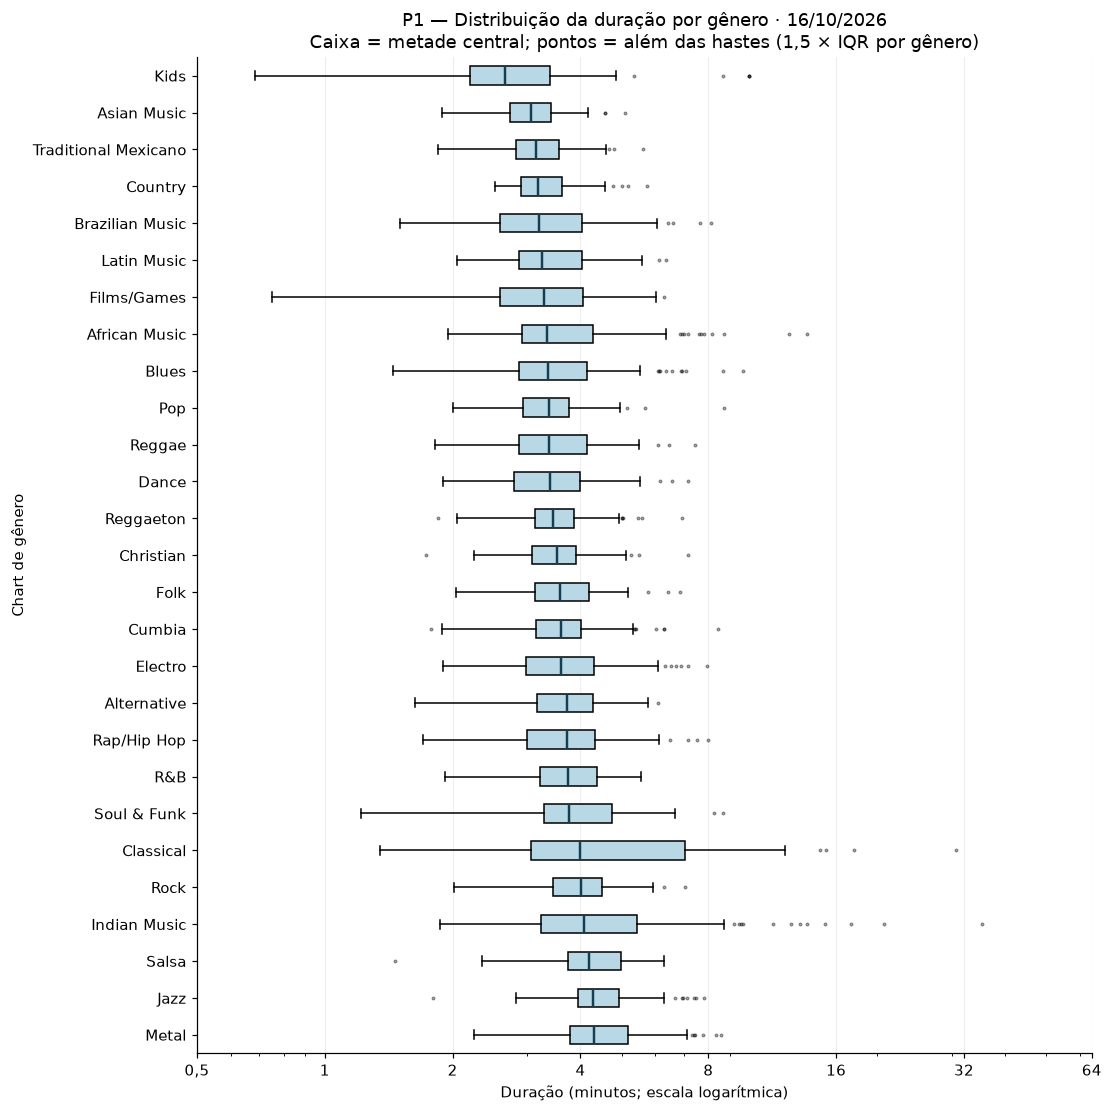

,ocorrencias,mediana_min,inicio_caixa_min,fim_caixa_min,maximo_min
genero,,,,,
Kids,100,2.66,2.20,3.38,9.98
Asian Music,100,3.07,2.73,3.40,5.08
Traditional Mexicano,100,3.14,2.82,3.55,5.60
Country,100,3.18,2.90,3.62,5.75
Brazilian Music,100,3.19,2.58,4.03,8.12
Latin Music,100,3.24,2.87,4.03,6.35
Films/Games,100,3.28,2.58,4.06,6.28
African Music,100,3.34,2.91,4.29,13.68
Blues,100,3.35,2.87,4.14,9.63


In [12]:
# Duração por gênero (boxplot)
resumo_duracao_vis = (
    df_generos_vis.groupby("genero")["duracao_s"]
    .agg(ocorrencias="size", mediana_s="median", minimo_s="min", maximo_s="max")
    .sort_values("mediana_s")
)
quartis_duracao_vis = df_generos_vis.groupby("genero")["duracao_s"].quantile([0.25, 0.75]).unstack()
resumo_duracao_vis["mediana_min"] = resumo_duracao_vis["mediana_s"] / 60
resumo_duracao_vis["inicio_caixa_min"] = quartis_duracao_vis[0.25] / 60
resumo_duracao_vis["fim_caixa_min"] = quartis_duracao_vis[0.75] / 60
resumo_duracao_vis["maximo_min"] = resumo_duracao_vis["maximo_s"] / 60
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    duracoes_vis = [
        df_generos_vis.loc[df_generos_vis["genero"].eq(genero_vis), "duracao_s"] / 60
        for genero_vis in resumo_duracao_vis.index
    ]
    # Compatibilidade com matplotlib 3.8 e com a orientação nomeada das versões recentes.
    orientacao_vis = ({"orientation": "horizontal"} if "orientation" in assinatura(eixo_vis.boxplot).parameters
                      else {"vert": False})
    caixas_vis = eixo_vis.boxplot(
        duracoes_vis, **orientacao_vis, patch_artist=True, whis=1.5,
        medianprops={"color": "#153e52", "linewidth": 1.6},
        flierprops={"marker": ".", "markersize": 3, "alpha": 0.5},
    )
    for caixa_vis in caixas_vis["boxes"]:
        caixa_vis.set_facecolor("#b8d8e5")
    eixo_vis.set_yticks(range(1, len(resumo_duracao_vis) + 1), resumo_duracao_vis.index)
    eixo_vis.invert_yaxis()
    eixo_vis.set_xscale("log")
    eixo_vis.set_xticks([0.5, 1, 2, 4, 8, 16, 32, 64])
    eixo_vis.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:g}".replace(".", ",")))
    eixo_vis.set_xlabel("Duração (minutos; escala logarítmica)")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P1 — Distribuição da duração por gênero · {data_retrato_vis}\n"
                       "Caixa = metade central; pontos = além das hastes (1,5 × IQR por gênero)")
    eixo_vis.grid(axis="x", alpha=0.2)
    plt.show()
display(resumo_duracao_vis[["ocorrencias", "mediana_min", "inicio_caixa_min", "fim_caixa_min", "maximo_min"]].round(2))

**Interpretação — P1:** a duração típica das músicas muda de um gênero para outro. Em Kids, a duração do meio da lista é de aproximadamente 2 minutos e 40 segundos; em Metal, é de 4 minutos e 19 segundos. Isso não significa que toda música de Metal seja mais longa que qualquer música de Kids: há músicas de durações diferentes dentro de cada gênero, como mostram as caixas e os pontos.

Classical tem maior variação na metade central das músicas, que vai de cerca de 3 minutos e 4 segundos a 7 minutos e 4 segundos. Em Asian Music, essa parte fica entre 2 minutos e 44 segundos e 3 minutos e 24 segundos. A caixa mais larga mostra essa diferença de durações dentro do próprio gênero.

Os pontos são músicas que ficam além das hastes da caixa, pela regra de 1,5 vez o intervalo entre o primeiro e o terceiro quartil (IQR). São durações mais afastadas do centro, que não indicam erro por si só. Esses limites são calculados por gênero e não precisam coincidir com a sinalização de qualidade já gravada no conjunto preparado.

As medianas são 159,5 s em Kids e 258,5 s em Metal, com 100 faixas em cada chart. A faixa mais longa dos charts de gênero tem 2.120 s (35 minutos e 20 segundos), em Indian Music. Ela foi mantida, mas esse caso isolado não resume o gênero inteiro. Fonte: seção 2, célula "Duração por gênero (boxplot)".

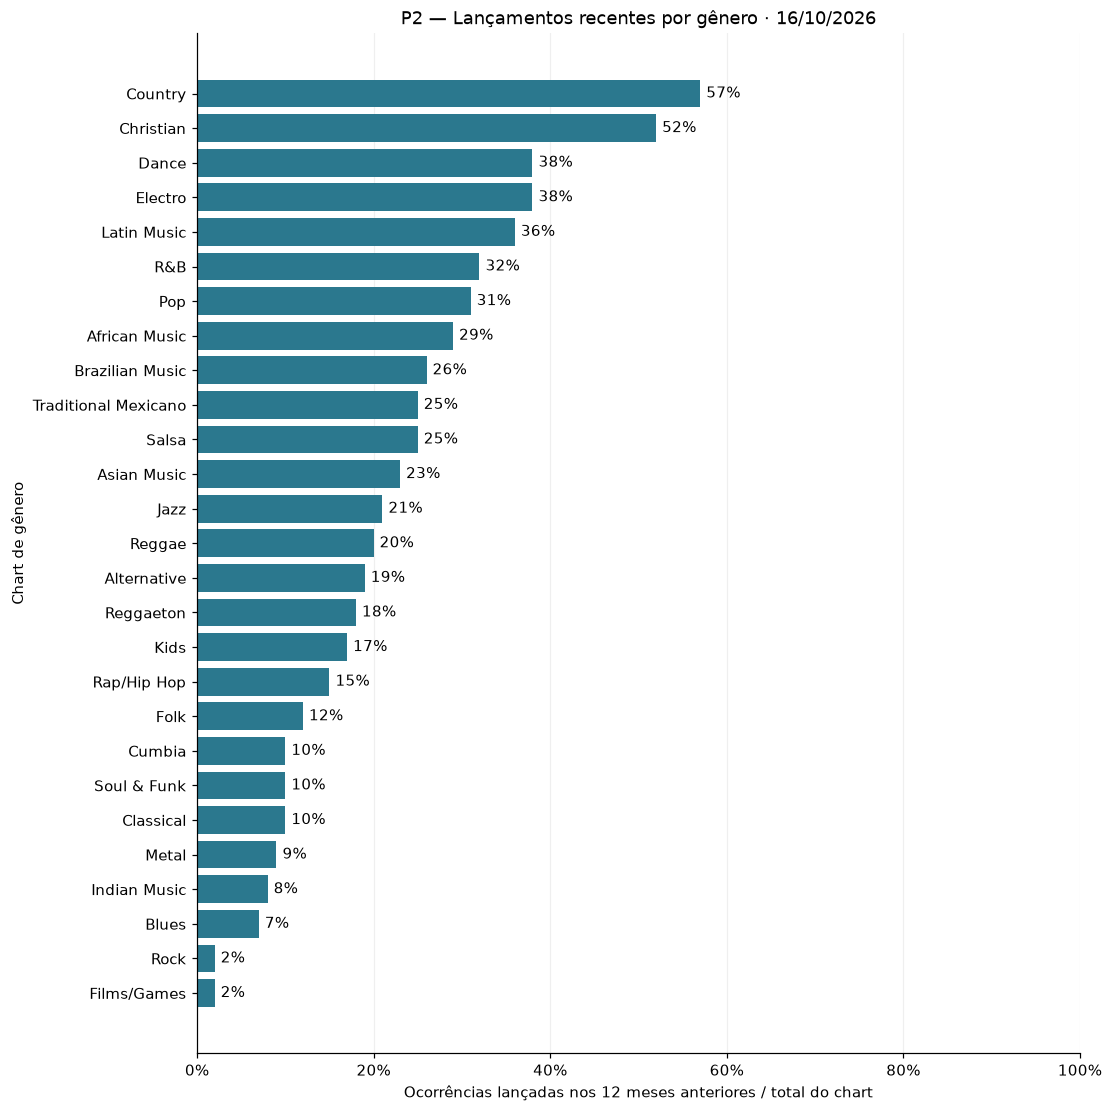

,recentes,ocorrencias,percentual
genero,,,
Films/Games,2,100,2.0
Rock,2,100,2.0
Blues,7,100,7.0
Indian Music,8,100,8.0
Metal,9,100,9.0
Classical,10,100,10.0
Soul & Funk,10,100,10.0
Cumbia,10,100,10.0
Folk,12,100,12.0


Janela inclusiva: 16/10/2025 a 16/10/2026.
Recentes: 592 de 2700 ocorrências. Lançamentos posteriores à coleta, fora do numerador: 1.


In [13]:
# Lançamentos nos 12 meses anteriores à coleta
inicio_janela_vis = df_generos_vis["data_coleta"] - pd.DateOffset(months=12)
df_generos_vis["recente_vis"] = (
    df_generos_vis["data_lancamento"].ge(inicio_janela_vis)
    & ~df_generos_vis["lancamento_posterior_coleta"]
)
resumo_recentes_vis = (
    df_generos_vis.groupby("genero")["recente_vis"]
    .agg(recentes="sum", ocorrencias="size")
)
resumo_recentes_vis["percentual"] = (
    100 * resumo_recentes_vis["recentes"] / resumo_recentes_vis["ocorrencias"]
)
resumo_recentes_vis = resumo_recentes_vis.sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_recentes_vis.index, resumo_recentes_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.0f}%" for valor in resumo_recentes_vis["percentual"]], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Ocorrências lançadas nos 12 meses anteriores / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P2 — Lançamentos recentes por gênero · {data_retrato_vis}")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_recentes_vis)
print(f"Janela inclusiva: {inicio_janela_vis.min():%d/%m/%Y} a {df_generos_vis['data_coleta'].max():%d/%m/%Y}.")
print(f"Recentes: {df_generos_vis['recente_vis'].sum()} de {len(df_generos_vis)} ocorrências. "
      f"Lançamentos posteriores à coleta, fora do numerador: "
      f"{df_generos_vis['lancamento_posterior_coleta'].sum()}.")

**Interpretação — P2:** alguns charts têm mais espaço para músicas lançadas recentemente. Em Country, mais da metade das faixas foi lançada no último ano: 57 de 100. Em Rock e Films/Games, foram apenas 2 de 100 em cada chart. Portanto, estar no topo não significa necessariamente ser uma novidade; o peso dos lançamentos recentes varia entre os gêneros.

Ao todo, 592 dos 2.700 registros de faixas nos charts de gênero (21,9%) são lançamentos entre 16/10/2025 e 16/10/2026, incluindo essas duas datas. A única faixa com lançamento posterior à coleta continua no total do seu chart, mas não conta como lançamento já ocorrido. Essa comparação descreve a idade dos lançamentos na coleta, sem acompanhar entradas e saídas dos charts ao longo do tempo. Fonte: seção 2, célula "Lançamentos nos 12 meses anteriores à coleta".

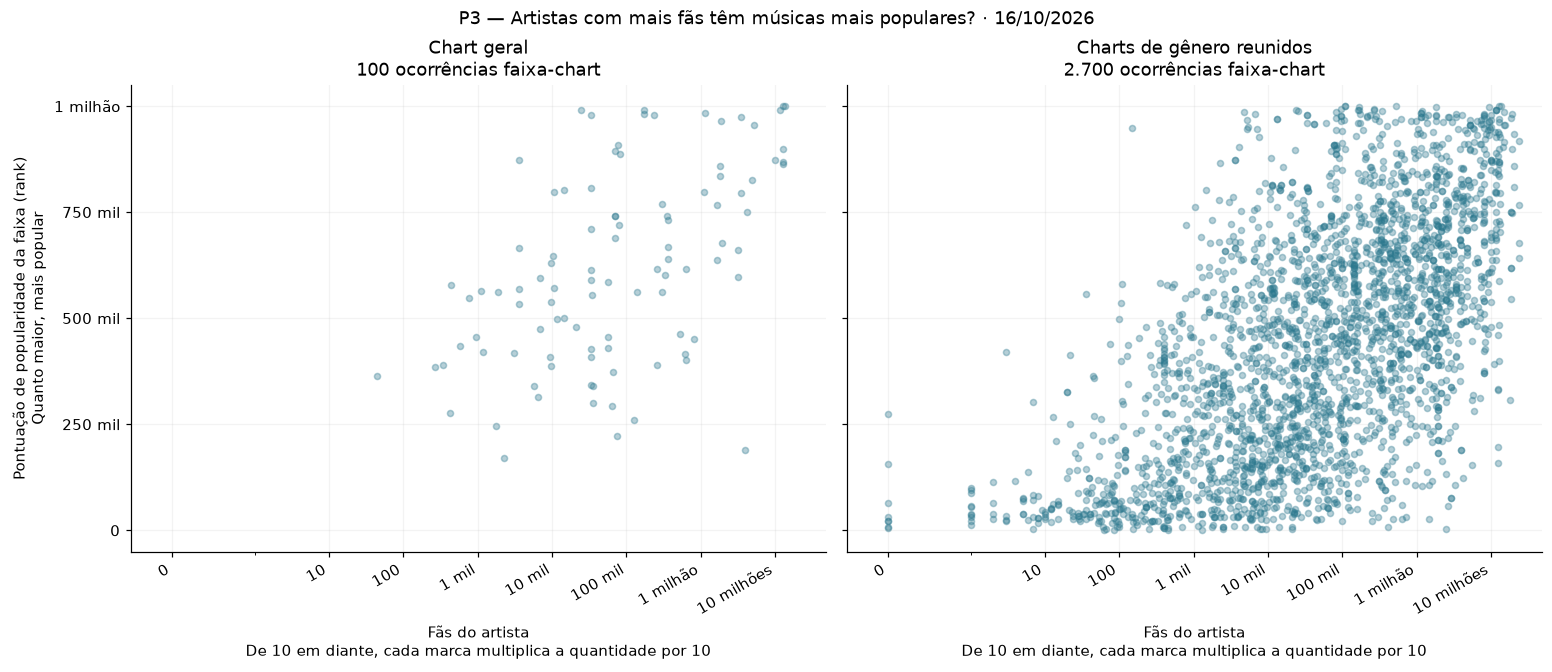

,recorte,ocorrencias,fas_iguais_zero,spearman
0,Chart geral,100,0,0.530
1,Charts de gênero reunidos,2700,8,0.601


In [14]:
# Fãs do artista e popularidade: chart geral e conjunto dos gêneros
# Spearman equivale à correlação de Pearson dos postos, com postos médios nos empates.
correlacoes_gerais_vis = []
limite_popularidade_vis = max(100_000, arredondar_para_cima(df_analise["rank"].max() / 100_000) * 100_000)
marcacoes_popularidade_vis = [limite_popularidade_vis * parte_vis / 4 for parte_vis in range(5)]
rotulos_popularidade_vis = [
    ("0" if valor_vis == 0 else
     f"{valor_vis / 1_000_000:g} milhão" if valor_vis == 1_000_000 else
     f"{valor_vis / 1_000_000:g} milhões" if valor_vis > 1_000_000 else
     f"{valor_vis / 1_000:g} mil").replace(".", ",")
    for valor_vis in marcacoes_popularidade_vis
]
with plt.rc_context(estilo_vis):
    figura_vis, eixos_vis = plt.subplots(1, 2, figsize=(14, 6), sharey=True, layout="constrained")
    for eixo_vis, (nome_vis, recorte_vis) in zip(
        eixos_vis, [("Chart geral", df_geral_vis), ("Charts de gênero reunidos", df_generos_vis)]
    ):
        correlacao_vis = recorte_vis["numero_fas"].rank().corr(recorte_vis["rank"].rank())
        correlacoes_gerais_vis.append({
            "recorte": nome_vis, "ocorrencias": len(recorte_vis),
            "fas_iguais_zero": int(recorte_vis["numero_fas"].eq(0).sum()),
            "spearman": correlacao_vis,
        })
        eixo_vis.scatter(recorte_vis["numero_fas"], recorte_vis["rank"], s=16, alpha=0.35, color="#2b788e")
        eixo_vis.set_xscale("symlog", linthresh=1)
        eixo_vis.set_xticks(
            [0, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 10_000_000],
            ["0", "10", "100", "1 mil", "10 mil", "100 mil", "1 milhão", "10 milhões"],
            rotation=30, ha="right",
        )
        # Margens na área do gráfico preservam os círculos inteiros, inclusive os de zero fãs.
        eixo_vis.set_xlim(-0.5, df_analise["numero_fas"].max() * 2)
        eixo_vis.set_ylim(-0.05 * limite_popularidade_vis, 1.05 * limite_popularidade_vis)
        eixo_vis.set_yticks(marcacoes_popularidade_vis, rotulos_popularidade_vis)
        eixo_vis.set_xlabel("Fãs do artista\nDe 10 em diante, cada marca multiplica a quantidade por 10")
        eixo_vis.set_title(f"{nome_vis}\n{len(recorte_vis):,} ocorrências faixa-chart".replace(",", "."))
        eixo_vis.grid(alpha=0.15)
    eixos_vis[0].set_ylabel("Pontuação de popularidade da faixa (rank)\nQuanto maior, mais popular")
    figura_vis.suptitle(f"P3 — Artistas com mais fãs têm músicas mais populares? · {data_retrato_vis}")
    plt.show()
display(pd.DataFrame(correlacoes_gerais_vis).round({"spearman": 3}))

In [15]:
# Exemplos de fãs e popularidade
# Exemplos observados nos charts de gênero, sem tratá-los como perfil de todo o conjunto.
exemplos_popularidade_vis = pd.concat([
    df_generos_vis.loc[df_generos_vis["numero_fas"].le(1_000)]
    .nlargest(1, "rank").assign(leitura="Poucos fãs, pontuação alta"),
    df_generos_vis.loc[df_generos_vis["numero_fas"].ge(1_000_000)]
    .nsmallest(1, "rank").assign(leitura="Muitos fãs, pontuação baixa"),
])
display(exemplos_popularidade_vis[["leitura", "genero", "artista", "titulo", "numero_fas", "rank"]])

,leitura,genero,artista,titulo,numero_fas,rank
2095,"Poucos fãs, pontuação alta",African Music,ISSAH,BADDIES IN BELGICA,150,948653
2621,"Muitos fãs, pontuação baixa",Kids,Frank Sinatra,Let It Snow! Let It Snow! Let It Snow! (with T...,2487314,2757


**Como ler:** cada bolinha representa uma faixa em um chart. Mais à direita significa mais fãs do artista; mais acima significa maior popularidade da música. Essa popularidade é a pontuação `rank` da Deezer: não é a posição de 1º ou 2º lugar, nem uma contagem de ouvintes ou reproduções. No eixo horizontal, 1 mil significa 1.000 fãs e 1 milhão significa 1.000.000. A partir de 10, cada marca multiplica a quantidade por dez, para que artistas com dezenas e com milhões de fãs caibam na mesma figura. Os pontos de zero fãs também são mantidos.

**Interpretação — P3, visão geral:** a quantidade de fãs, sozinha, não determina a popularidade da música. Ter dez vezes mais fãs não implica ter dez vezes mais popularidade. Ainda existe uma tendência no conjunto: artistas com mais fãs tendem a ter faixas mais populares. Mas há exceções, e artistas com poucos fãs também podem ter músicas muito populares.

Por exemplo, "BADDIES IN BELGICA", de ISSAH, tem 150 fãs do artista e 948.653 pontos de popularidade. A faixa de Frank Sinatra exibida na tabela tem 2.487.314 fãs do artista e 2.757 pontos. Esses dois casos ilustram por que o número de fãs não basta para prever o resultado de uma música; não dizem com que frequência as exceções acontecem.

A tendência positiva é resumida pela correlação de Spearman: 0,53 nos 100 registros do chart geral e 0,60 nos 2.700 dos charts de gênero reunidos. Esses valores medem quanto as duas ordenações caminham juntas; não significam que 53% ou 60% da popularidade seja causada pelos fãs. O retrato mostra uma associação e não permite afirmar que mais fãs causem mais popularidade. Fontes: seção 2, células "Fãs do artista e popularidade: chart geral e conjunto dos gêneros" e "Exemplos de fãs e popularidade".

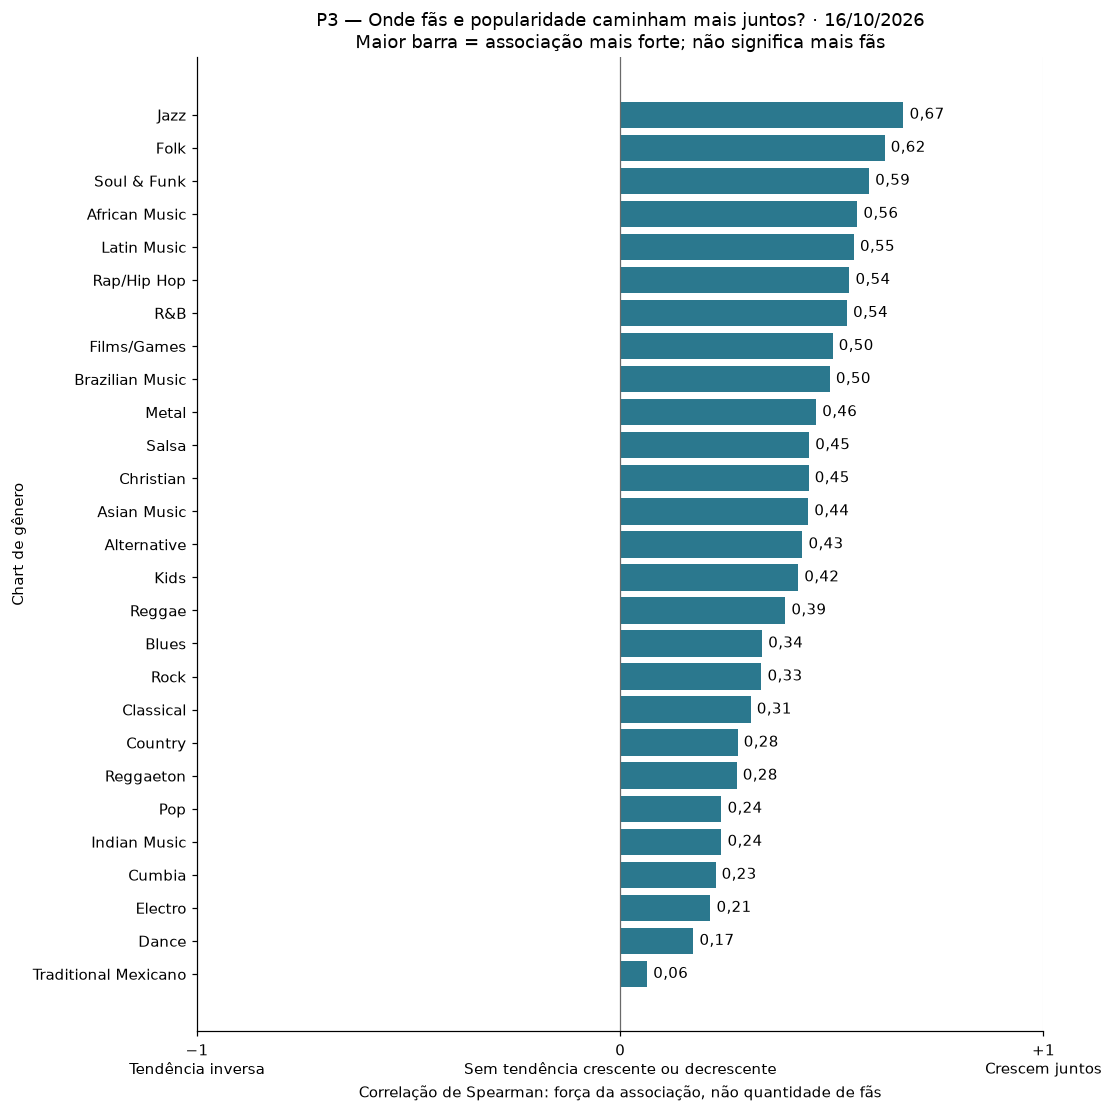

,ocorrencias,mediana_fas_por_ocorrencia,spearman
genero,,,
Traditional Mexicano,100,510083.0,0.064
Dance,100,104057.0,0.173
Electro,100,41978.0,0.213
Cumbia,100,11909.0,0.225
Indian Music,100,1258.5,0.239
Pop,100,613963.0,0.239
Reggaeton,100,1760661.0,0.275
Country,100,34805.0,0.277
Classical,100,1693.5,0.308


In [16]:
# Associação entre fãs e popularidade dentro de cada gênero
correlacoes_genero_vis = pd.DataFrame([
    {"genero": genero_vis, "ocorrencias": len(grupo_vis),
     "mediana_fas_por_ocorrencia": grupo_vis["numero_fas"].median(),
     "spearman": grupo_vis["numero_fas"].rank().corr(grupo_vis["rank"].rank())}
    for genero_vis, grupo_vis in df_generos_vis.groupby("genero")
]).set_index("genero").sort_values("spearman")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(correlacoes_genero_vis.index, correlacoes_genero_vis["spearman"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[f"{valor:.2f}".replace(".", ",") for valor in correlacoes_genero_vis["spearman"]], padding=4,
    )
    eixo_vis.set_xlim(-1, 1)
    eixo_vis.set_xticks(
        [-1, 0, 1],
        ["−1\nTendência inversa", "0\nSem tendência crescente ou decrescente", "+1\nCrescem juntos"],
    )
    eixo_vis.axvline(0, color="dimgray", linewidth=0.8)
    eixo_vis.set_xlabel("Correlação de Spearman: força da associação, não quantidade de fãs")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P3 — Onde fãs e popularidade caminham mais juntos? · {data_retrato_vis}\n"
                       "Maior barra = associação mais forte; não significa mais fãs")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(correlacoes_genero_vis.round({"spearman": 3}))

**Interpretação — P3, por gênero:** Jazz aparece em primeiro porque, dentro desse chart, a tendência de artistas com mais fãs terem músicas mais populares é mais forte. Isso não quer dizer que Jazz tenha mais fãs que os outros gêneros. Em Traditional Mexicano, essa tendência é bem menos nítida: saber que um artista tem mais fãs ajuda pouco a acompanhar a ordem de popularidade das faixas.

A medida dessa associação é 0,67 em Jazz e 0,06 em Traditional Mexicano, considerando 100 faixas em cada chart. Quanto mais perto de +1, mais as duas ordenações caminham juntas; perto de zero, essa tendência é pouco marcada. Os 27 charts têm valores positivos neste retrato, mas nenhum chega à correspondência perfeita de +1.

A diferença entre associação e quantidade de fãs aparece também na tabela: a mediana de fãs do artista nas 100 faixas de Jazz é 778,5; nas 100 de Pop, é 613.963, embora a associação em Pop seja menor, de 0,24. Assim, estar no topo deste gráfico não significa ter o maior número de fãs. Esses resultados descrevem os charts na data da coleta e não garantem que o padrão se repita em outras datas. Fonte: seção 2, célula "Associação entre fãs e popularidade dentro de cada gênero".

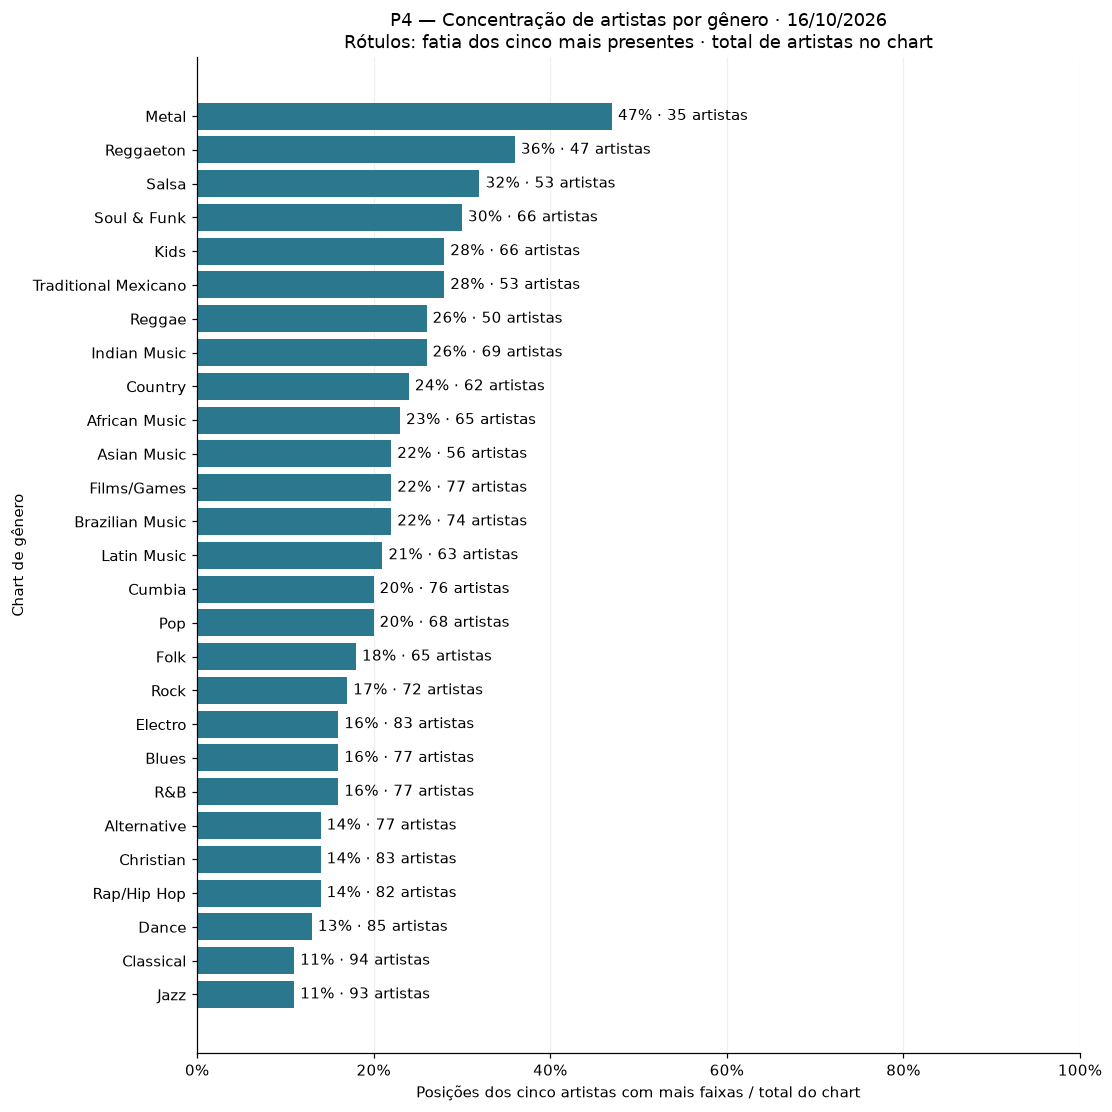

,id_chart,ocorrencias,artistas_distintos,posicoes_cinco_artistas,percentual
genero,,,,,
Jazz,129,100,93,11,11.0
Classical,98,100,94,11,11.0
Dance,113,100,85,13,13.0
Rap/Hip Hop,116,100,82,14,14.0
Christian,186,100,83,14,14.0
Alternative,85,100,77,14,14.0
R&B,165,100,77,16,16.0
Blues,153,100,77,16,16.0
Electro,106,100,83,16,16.0


In [17]:
# Concentração das posições nos cinco artistas mais presentes
contagem_artistas_vis = (
    df_generos_vis.groupby(["id_chart", "genero", "id_artista"])
    .size().rename("posicoes").reset_index()
)
# Desempate por identificador; o total das cinco maiores contagens não muda em empates.
cinco_artistas_vis = (
    contagem_artistas_vis.sort_values(["posicoes", "id_artista"], ascending=[False, True])
    .groupby(["id_chart", "genero"]).head(5)
)
resumo_concentracao_vis = df_generos_vis.groupby(["id_chart", "genero"]).agg(
    ocorrencias=("id_faixa", "size"), artistas_distintos=("id_artista", "nunique")
)
resumo_concentracao_vis["posicoes_cinco_artistas"] = (
    cinco_artistas_vis.groupby(["id_chart", "genero"])["posicoes"].sum()
)
resumo_concentracao_vis["percentual"] = (
    100 * resumo_concentracao_vis["posicoes_cinco_artistas"] / resumo_concentracao_vis["ocorrencias"]
)
resumo_concentracao_vis = resumo_concentracao_vis.reset_index().set_index("genero").sort_values("percentual")
with plt.rc_context(estilo_vis):
    figura_vis, eixo_vis = plt.subplots(figsize=(10, 10), layout="constrained")
    barras_vis = eixo_vis.barh(resumo_concentracao_vis.index, resumo_concentracao_vis["percentual"], color="#2b788e")
    eixo_vis.bar_label(
        barras_vis,
        labels=[
            f"{linha_vis.percentual:.0f}% · {linha_vis.artistas_distintos} artistas"
            for linha_vis in resumo_concentracao_vis.itertuples()
        ], padding=4,
    )
    eixo_vis.set_xlim(0, 100)
    eixo_vis.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    eixo_vis.set_xlabel("Posições dos cinco artistas com mais faixas / total do chart")
    eixo_vis.set_ylabel("Chart de gênero")
    eixo_vis.set_title(f"P4 — Concentração de artistas por gênero · {data_retrato_vis}\n"
                       "Rótulos: fatia dos cinco mais presentes · total de artistas no chart")
    eixo_vis.grid(axis="x", alpha=0.2)
    eixo_vis.set_axisbelow(True)
    plt.show()
display(resumo_concentracao_vis)

**Interpretação — P4:** em alguns charts, os mesmos artistas aparecem várias vezes. Em Metal, apenas cinco artistas ocupam quase metade da lista: 47 das 100 posições. Em Jazz e Classical, os cinco artistas mais presentes ocupam 11 das 100 posições em cada chart. Nesses dois casos, a lista distribui mais posições entre artistas diferentes.

Isso também aparece na quantidade de nomes: Metal tem 35 artistas distintos, Jazz tem 93 e Classical tem 94, todos em charts de 100 faixas. Portanto, listas do mesmo tamanho podem dar espaço a quantidades bem diferentes de artistas. Estamos contando posições ocupadas; o gráfico não informa a participação desses artistas nas reproduções ou na audiência. Fonte: seção 2, célula "Concentração das posições nos cinco artistas mais presentes".

## 3. Amostragem e representatividade

Apresente uma breve análise sobre a representatividade dos dados utilizados, abordando:

- A origem e a abrangência do conjunto de dados.
- Se os registros representam adequadamente o problema investigado.
- Possíveis limitações ou vieses que possam influenciar os resultados.

Não é obrigatório implementar um procedimento de amostragem. Caso utilize uma amostra, explique como os registros foram selecionados.

In [18]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 4. Aplicação de Machine Learning

Implemente uma aplicação simples de aprendizagem supervisionada, por **classificação** (prever uma categoria ou classe) ou **regressão** (estimar um valor numérico). A implementação deverá contemplar:

1. Definição do problema preditivo.
2. Identificação da variável-alvo (*target*) e das características utilizadas (*features*).
3. Separação dos dados para treinamento e teste.
4. Treinamento de um modelo e realização de previsões.
5. Avaliação dos resultados utilizando pelo menos uma métrica adequada ao problema.

Caso o conjunto de dados original não possua características adequadas para uma aplicação supervisionada, outro conjunto de dados pode ser utilizado exclusivamente nesta etapa, com uma breve justificativa.

**Resposta do grupo:**

[Informe o problema preditivo, a variável-alvo e as características utilizadas.]

In [19]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Explique brevemente a métrica obtida e interprete o desempenho do modelo.]

## 5. Conclusões do RA3

Apresente uma conclusão geral do RA3, contemplando:

- Principais resultados identificados nas análises estatísticas e nas visualizações.
- Interpretação do desempenho do modelo de Machine Learning.
- Limitações dos dados e das análises realizadas.
- Relação dos resultados com o problema definido no projeto.

**Resposta do grupo:**

[Preencha aqui.]